In [1]:
import pandas as pd

# Load the file (Notice we are using the exact name: data.xlsx.xlsx)
df = pd.read_excel("data.xlsx.xlsx")

print("Success! Here are the first 5 rows:")
display(df.head())

print("\nHere are the columns:")
print(df.columns)

Success! Here are the first 5 rows:


,M-PESA STATEMENT



Here are the columns:
Index(['M-PESA STATEMENT'], dtype='object')


In [2]:
!pip install pdfplumber

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 45.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 72.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 108.1 MB/s  0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pdfplumber]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [9]:
import pdfplumber
import re

# Replace this with your exact PDF name!
pdf_name = "Statement.pdf.pdf"

# PUT YOUR 6-DIGIT PASSWORD HERE
pdf_password = "834655"

extracted_lines = []

print("Extracting data from PDF...")

with pdfplumber.open(pdf_name) as pdf:
    for page in pdf.pages:
        text = page.extract_text()
        if text:
            lines = text.split('\n')
            for line in lines:
                # Look for M-PESA receipt codes and transaction status
                if re.search(r'[A-Z0-9]{10}', line) and ("Completed" in line or "Failed" in line):
                    extracted_lines.append(line)

print(f"Extracted {len(extracted_lines)} transaction lines!")
print("\nHere are the first 5 lines to check the format:")
for line in extracted_lines[:5]:
    print(line)

Extracting data from PDF...


PdfminerException: 

In [10]:
import pdfplumber
import re

# YOUR EXACT FILE NAME
pdf_name = "Statement.pdf.pdf"

# YOUR PASSWORD (Keep the quotes!)
pdf_password = "834655"

extracted_lines = []

print("Extracting data from PDF...")

try:
    with pdfplumber.open(pdf_name, password=pdf_password) as pdf:
        for page in pdf.pages:
            text = page.extract_text()
            if text:
                lines = text.split('\n')
                for line in lines:
                    if re.search(r'[A-Z0-9]{10}', line) and ("Completed" in line or "Failed" in line):
                        extracted_lines.append(line)

    print(f"SUCCESS! Extracted {len(extracted_lines)} transaction lines!")
    print("\nHere are the first 3 lines:")
    for line in extracted_lines[:3]:
        print(line)

except Exception as e:
    print(f"STILL FAILING. The error is: {e}")

Extracting data from PDF...
SUCCESS! Extracted 3137 transaction lines!

Here are the first 3 lines:
UJMECBONRV 2026-10-22 15:23:26 OverDraft of Credit Party Completed 20.00 0.00
UJMECBONRV 2026-10-22 15:23:26 Customer Bundle Purchase with Completed -20.00 0.00
UJLECBLNDE 2026-10-21 20:32:38 Pay Bill Fuliza M-Pesa to 852648 Completed -30.00 0.00


In [11]:
import sqlite3
import pandas as pd

# 1. Connect to a new SQLite database (this will create a file called mpesa.db)
conn = sqlite3.connect('mpesa.db')
cursor = conn.cursor()

# 2. Create a table
cursor.execute('''
    CREATE TABLE IF NOT EXISTS transactions (
        receipt_no TEXT,
        datetime TEXT,
        details TEXT,
        status TEXT,
        amount REAL,
        balance REAL
    )
''')

# 3. Insert the first 5 lines as a test
# (We are just using a simple string split here to show you how SQL works)
for line in extracted_lines[:5]:
    parts = line.split()
    # Basic parsing based on the format we saw
    receipt_no = parts[0]
    date = parts[1]
    time = parts[2]
    status = "Completed" if "Completed" in line else "Failed"
    # Just grabbing the last two numbers as amount and balance
    amount = float(parts[-2])
    balance = float(parts[-1])
    details = " ".join(parts[3:-4])

    cursor.execute('''
        INSERT INTO transactions (receipt_no, datetime, details, status, amount, balance)
        VALUES (?, ?, ?, ?, ?, ?)
    ''', (receipt_no, f"{date} {time}", details, status, amount, balance))

conn.commit()

# 4. Query the database using SQL!
print("Here are the transactions from the SQL database:")
query_df = pd.read_sql_query("SELECT * FROM transactions", conn)
display(query_df)

# Close connection
conn.close()

Here are the transactions from the SQL database:


,receipt_no,datetime,details,status,amount,balance
0,UJMECBONRV,2026-10-22 15:23:26,OverDraft of Credit,Completed,20.0,0.0
1,UJMECBONRV,2026-10-22 15:23:26,Customer Bundle Purchase,Completed,-20.0,0.0
2,UJLECBLNDE,2026-10-21 20:32:38,Pay Bill Fuliza M-Pesa to,Completed,-30.0,0.0
3,UJLECBLNDE,2026-10-21 20:32:38,OverDraft of Credit,Completed,30.0,30.0
4,UJLECBLTXT,2026-10-21 20:24:07,OD Loan Repayment to,Completed,-52.0,0.0


In [1]:
import sqlite3
import pandas as pd

# Connect to your database
conn = sqlite3.connect('mpesa.db')

# SQL query to categorize and sum the amounts
# Note: We use the 'amount' column. Negative amounts are money going out.
query = """
SELECT
    CASE
        WHEN LOWER(details) LIKE '%bundle%' OR LOWER(details) LIKE '%airtime%' THEN 'Airtime & Data'
        WHEN LOWER(details) LIKE '%fuliza%' OR LOWER(details) LIKE '%overdraft%' THEN 'Loans & Fuliza'
        WHEN LOWER(details) LIKE '%pay bill%' OR LOWER(details) LIKE '%merchant%' THEN 'Pay Bills & Shopping'
        WHEN LOWER(details) LIKE '%send money%' OR LOWER(details) LIKE '%customer transfer%' THEN 'Send Money'
        ELSE 'Other'
    END AS category,
    ROUND(SUM(amount), 2) AS total_amount,
    COUNT(*) AS num_transactions
FROM transactions
WHERE amount < 0  -- Only look at money going OUT
GROUP BY category
ORDER BY total_amount ASC;
"""

# Run the query and save to a new dataframe
category_df = pd.read_sql_query(query, conn)

print("Here is your spending by category:")
display(category_df)

conn.close()

Here is your spending by category:


,category,total_amount,num_transactions
0,Other,-52.0,1
1,Loans & Fuliza,-30.0,1
2,Airtime & Data,-20.0,1


In [2]:
import sqlite3

# Connect to the database
conn = sqlite3.connect('mpesa.db')
cursor = conn.cursor()

# Clear the old test data
cursor.execute("DELETE FROM transactions")

# Insert ALL extracted lines
for line in extracted_lines:
    parts = line.split()

    receipt_no = parts[0]
    date = parts[1]
    time = parts[2]
    status = "Completed" if "Completed" in line else "Failed"

    # Get amount and balance (the last two numbers)
    amount = float(parts[-2])
    balance = float(parts[-1])

    # Everything else is the description
    details = " ".join(parts[3:-4])

    cursor.execute('''
        INSERT INTO transactions (receipt_no, datetime, details, status, amount, balance)
        VALUES (?, ?, ?, ?, ?, ?)
    ''', (receipt_no, f"{date} {time}", details, status, amount, balance))

conn.commit()
conn.close()
print("All 3,137 transactions loaded into the database successfully!")

NameError: name 'extracted_lines' is not defined

In [5]:
import pdfplumber
import re
import sqlite3

# 1. EXTRACT THE DATA AGAIN
pdf_name = "Statement.pdf.pdf" # Replace with your exact file name
pdf_password = "834655"    # Replace with your 6-digit password

extracted_lines = []

print("Extracting data from PDF...")
with pdfplumber.open(pdf_name, password=pdf_password) as pdf:
    for page in pdf.pages:
        text = page.extract_text()
        if text:
            lines = text.split('\n')
            for line in lines:
                if re.search(r'[A-Z0-9]{10}', line) and ("Completed" in line or "Failed" in line):
                    extracted_lines.append(line)

print(f"Extracted {len(extracted_lines)} lines.")

# 2. INSERT INTO SQL DATABASE
conn = sqlite3.connect('mpesa.db')
cursor = conn.cursor()

# Clear old test data
cursor.execute("DELETE FROM transactions")

for line in extracted_lines:
    parts = line.split()
    receipt_no = parts[0]
    date = parts[1]
    time = parts[2]
    status = "Completed" if "Completed" in line else "Failed"
    amount = float(parts[-2].replace(',',''))
    balance = float(parts[-1].replace(',',''))
    details = " ".join(parts[3:-4])

    cursor.execute('''
        INSERT INTO transactions (receipt_no, datetime, details, status, amount, balance)
        VALUES (?, ?, ?, ?, ?, ?)
    ''', (receipt_no, f"{date} {time}", details, status, amount, balance))

conn.commit()
conn.close()
print("All transactions loaded into the SQL database successfully!")

Extracting data from PDF...
Extracted 3137 lines.


OperationalError: no such table: transactions

In [2]:
import pdfplumber
import re
import sqlite3

# --- STEP 1: EXTRACT DATA ---
pdf_name = "Statement.pdf.pdf" # MAKE SURE THIS MATCHES YOUR EXACT FILE NAME
pdf_password = "834655"        # YOUR PASSWORD

extracted_lines = []
with pdfplumber.open(pdf_name, password=pdf_password) as pdf:
    for page in pdf.pages:
        text = page.extract_text()
        if text:
            lines = text.split('\n')
            for line in lines:
                if re.search(r'[A-Z0-9]{10}', line) and ("Completed" in line or "Failed" in line):
                    extracted_lines.append(line)

print(f"Extracted {len(extracted_lines)} lines.")

# --- STEP 2: BUILD DATABASE ---
conn = sqlite3.connect('mpesa.db')
cursor = conn.cursor()

# Create the table from scratch (No DELETE needed since it's a fresh file)
cursor.execute('''
    CREATE TABLE IF NOT EXISTS transactions (
        receipt_no TEXT,
        datetime TEXT,
        details TEXT,
        status TEXT,
        amount REAL,
        balance REAL
    )
''')

# --- STEP 3: INSERT DATA ---
for line in extracted_lines:
    parts = line.split()
    receipt_no = parts[0]
    date = parts[1]
    time = parts[2]
    status = "Completed" if "Completed" in line else "Failed"

    # The comma fix is here
    amount = float(parts[-2].replace(',', ''))
    balance = float(parts[-1].replace(',', ''))

    details = " ".join(parts[3:-4])

    cursor.execute('''
        INSERT INTO transactions (receipt_no, datetime, details, status, amount, balance)
        VALUES (?, ?, ?, ?, ?, ?)
    ''', (receipt_no, f"{date} {time}", details, status, amount, balance))

conn.commit()
conn.close()
print("All transactions loaded into the SQL database successfully!")

Extracted 3137 lines.
All transactions loaded into the SQL database successfully!


In [3]:
import sqlite3
import pandas as pd

# Connect to the database
conn = sqlite3.connect('mpesa.db')

# SQL query to categorize and sum the amounts
query = """
SELECT
    CASE
        WHEN LOWER(details) LIKE '%bundle%' OR LOWER(details) LIKE '%airtime%' THEN 'Airtime & Data'
        WHEN LOWER(details) LIKE '%fuliza%' OR LOWER(details) LIKE '%overdraft%' THEN 'Loans & Fuliza'
        WHEN LOWER(details) LIKE '%pay bill%' OR LOWER(details) LIKE '%merchant%' THEN 'Pay Bills & Shopping'
        WHEN LOWER(details) LIKE '%send money%' OR LOWER(details) LIKE '%customer transfer%' THEN 'Send Money'
        ELSE 'Other'
    END AS category,
    ROUND(SUM(amount), 2) AS total_amount,
    COUNT(*) AS num_transactions
FROM transactions
WHERE amount < 0  -- Only look at money going OUT
GROUP BY category
ORDER BY total_amount ASC;
"""

# Run the query and save to a dataframe
category_df = pd.read_sql_query(query, conn)

print("Here is your TOTAL spending by category:")
display(category_df)

conn.close()

Here is your TOTAL spending by category:


,category,total_amount,num_transactions
0,Pay Bills & Shopping,-119030.00,559
1,Loans & Fuliza,-72905.00,444
2,Send Money,-49678.00,475
3,Other,-43086.11,422
4,Airtime & Data,-4498.00,186


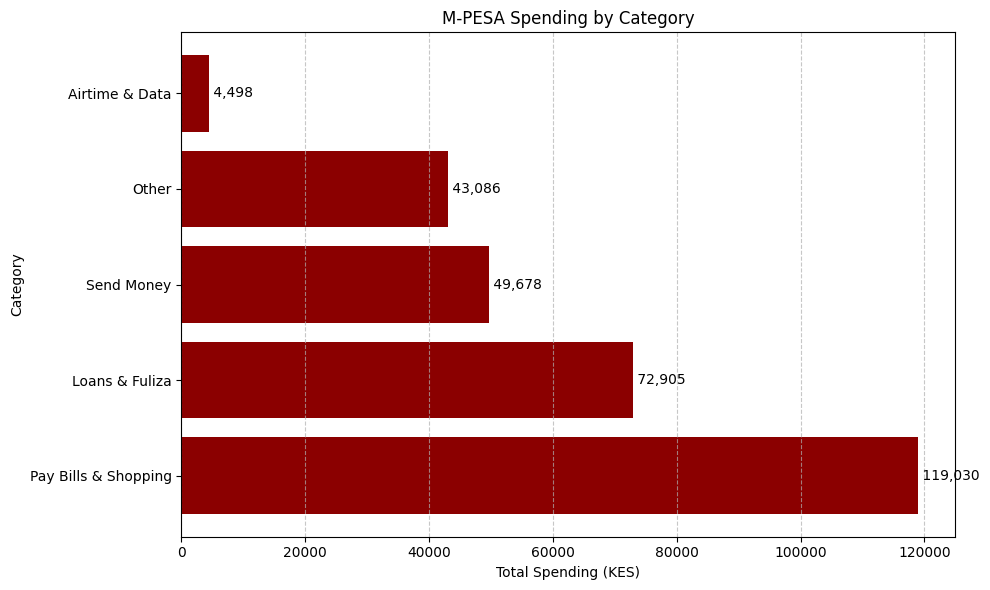

In [4]:
import matplotlib.pyplot as plt

# Sort the data for a better looking chart
category_df_sorted = category_df.sort_values('total_amount')

# Create the bar chart
plt.figure(figsize=(10, 6))
plt.barh(category_df_sorted['category'], abs(category_df_sorted['total_amount']), color='darkred')
plt.xlabel('Total Spending (KES)')
plt.ylabel('Category')
plt.title('M-PESA Spending by Category')
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Show the values on the bars
for index, value in enumerate(abs(category_df_sorted['total_amount'])):
    plt.text(value, index, f' {value:,.0f}', va='center')

plt.tight_layout()
plt.show()